# 01 · Preprocessing — Wang 2019 Glioblastoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony on `sample`), embed, remove detached islands, split the manifold
into transcriptional compartments, and read **Gate 1** (sample-mixing + manifold continuity)
off the regenerated embedding plus a per-neighbourhood metric (iLISI) across an
integration-strength sweep — never a scalar alone.

Wang 2019 is IDH-wildtype glioblastoma profiled by 10x across 10 samples. Glioblastoma
malignant cells carry strong patient-private (CNV-driven) identity — the raw per-sample
same-neighbour fraction is **0.99** (near-total segregation) — so batch integration is the
decisive Gate-1 concern and strong Harmony integration is required. Every tunable choice is
*derived from this dataset*, not inherited from the Puram2017 skeleton. Deliverable:
`processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

### Paths
The dataset directory carries a `-1` re-analysis suffix; the *raw* input folder does not, so
the raw path strips it while every output path keeps it. The `<Category>/` partition puts
this notebook two levels deeper than the Puram2017 reference, so the relative path logic is
adapted accordingly — the notebook runs in place.

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Wang2019_Brain-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Brain
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

raw_name = 'Data_' + name[:-2] if name.endswith('-1') else 'Data_' + name  # raw folder has no -1
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Wang2019_Brain-1 | category: Brain | raw: Data_Wang2019_Brain


### Load malignant compartment
Wang et al. annotate cell type directly; we take their `Malignant` calls. The loader
auto-detects UMI counts (`Exp_data_UMIcounts.mtx`), normalizes total and `log1p`-transforms.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
print('full atlas:', adata.shape)
print('cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

full atlas: (16317, 33545)
cell types: {'Malignant': 9916, 'Oligodendrocyte': 3711, 'Myeloid': 2396, 'Astrocyte': 248, 'Endothelial': 46}
malignant: (9916, 33545) | samples: 10
expression: X max 7.51 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span two orders of magnitude (38 → 2732). Rather than a
round-number cut, we find the largest **multiplicative** cliff in the sorted counts and cut
at its geometric mean — the natural separatrix between tumour-bearing samples and thin
spillover. The largest gap is 396 → 143 (2.8×), giving a threshold of 237.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print('adjacent ratios:', np.round(ratios,2))
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [2732 2492 1293 1112  938  687  396  143   85   38]
adjacent ratios: [1.1  1.93 1.16 1.19 1.37 1.73 2.77 1.68 2.24]
largest gap: 396 -> 143 (ratio 2.77)
derived threshold (geometric mean across the gap) = 237
kept 7/10 samples -> 9650 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is chosen by an integration-strength sweep read with **iLISI** (inverse Simpson over
sample labels in each cell\'s k-neighbourhood; higher = better mixing, max = n_samples). We
take the smallest theta past which mixing plateaus. Given the extreme raw patient segregation
in GBM, theta is swept up to 20. PC count (20) follows the 10x precedents (Kürten/Sun/Lee) and
the scree (cumulative variance flattens past ~20 PCs); UMAP spread 1.3.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
print('cumulative variance @ 20/30/40 PCs:',
      np.round(np.cumsum(adata.uns['pca']['variance_ratio'])[[19,29,39]],3))

def ilisi(rep, labels, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes
    out = np.empty(len(codes))
    for i in range(len(codes)):
        _, cnt = np.unique(codes[idx[i]], return_counts=True); p = cnt/cnt.sum()
        out[i] = 1.0/(p**2).sum()
    return out

def same_frac(rep, labels, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = np.asarray(labels)
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))

nsamp = adata.obs['sample'].nunique()
pre = same_frac(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values)
print(f'pre-Harmony same-sample neighbour fraction (n_pcs=20) = {pre:.3f}  (1.0 = full segregation)')
sweep = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    il = ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values)
    sweep[th] = round(float(np.median(il)), 2)
print(f'iLISI median by theta (max={nsamp}):', sweep)
theta = 10
print(f'selected theta = {theta} (iLISI plateaus ~1.9; theta=20 adds no mixing and sheds specks)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
adata.obs['iLISI'] = ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2113 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2113
cumulative variance @ 20/30/40 PCs: [0.438 0.461 0.477]
pre-Harmony same-sample neighbour fraction (n_pcs=20) = 0.992  (1.0 = full segregation)
iLISI median by theta (max=7): {2: 1.07, 5: 1.69, 10: 1.87, 20: 1.8}
selected theta = 10 (iLISI plateaus ~1.9; theta=20 adds no mixing and sheds specks)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous manifold.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('kept', adata.shape[0], 'cells on one connected component')

removed 16 cells in 1 detached islands
kept 9634 cells on one connected component


### Compartment split + cell cycle (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold\'s lobes. The published
`cell_cycle_phase` field is empty for malignant cells, so cell cycle is scored fresh (scanpy
S/G2M gene sets). Lobes are labelled by biology to test the Kürten lobe-identity fork: is the
developmental axis confined to a low-cycling lobe (scoping justified), or orthogonal to
proliferation (keep the whole manifold)? The scope decision is finalised in 02 from the
signature geography.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL',
           'PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2',
           'UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM',
           'CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B',
             'MKI67','TMPO','CENPF','TACC3','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11',
             'ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','CDC20','TTK','CDC25C','KIF2C',
             'RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1',
             'ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['cycling'] = (adata.obs['phase'] != 'G1').astype(int)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cell-cycle phase:', adata.obs['phase'].value_counts().to_dict())
print('cycling fraction per lobe:',
      adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())

lobe sizes: {'2': 4552, '1': 2975, '0': 2107}
cell-cycle phase: {'G1': 7334, 'G2M': 1446, 'S': 854}
cycling fraction per lobe: {'0': 0.228, '1': 0.283, '2': 0.214}


### Gate 1 — batch mixing & manifold continuity (read on the embedding)
The Kürten fork warns against passing Gate 1 on a mixing scalar that scores a per-patient
*archipelago* as integrated. The read is therefore made on the embedding and on the lobe
composition, with iLISI as corroboration — **not** on the absolute iLISI value. Three facts
decide it: (i) the manifold is **one connected component**; (ii) **no lobe is a single
patient** — each lobe's dominant sample holds only ~1/3 of its cells and 6–7 of 7 samples are
represented in every lobe (the theta=2 monochrome patient lobes are gone); (iii) Harmony cut
the same-sample neighbour fraction from 0.99 to ~0.6 (random baseline 0.19).

Mixing is **partial, not complete**: iLISI median is only ~1.9/7 and a majority of cells still
sit in a locally patient-enriched neighbourhood. That residual identity is expected — GBM
malignant cells carry strong patient-private CNV programs that batch correction cannot (and
should not) erase — and it is *not* an archipelago: it is distributed within a continuous,
multi-sample manifold rather than separating patients into islands. On that basis Gate 1 = GO.
The deliverable `samples.pdf` follows.

per-lobe dominant-sample share (an archipelago would show a lobe ~1.0 from one patient):
  lobe 0: n=2107 dominant SF10022=0.27 | samples>=5% = 6/7
  lobe 1: n=2975 dominant SF10022=0.30 | samples>=5% = 7/7
  lobe 2: n=4552 dominant SF4297=0.35 | samples>=5% = 6/7
connected components on the neighbour graph = 1
iLISI median 1.87/7 (mean 2.13); frac cells iLISI>=2 = 0.45
read: 1 connected component + every lobe multi-sample (no monochrome island) + same-sample frac 0.99->~0.6; residual local patient identity is expected GBM CNV structure, not an archipelago
Gate 1: continuous, archipelago-free, multi-sample manifold -> GO


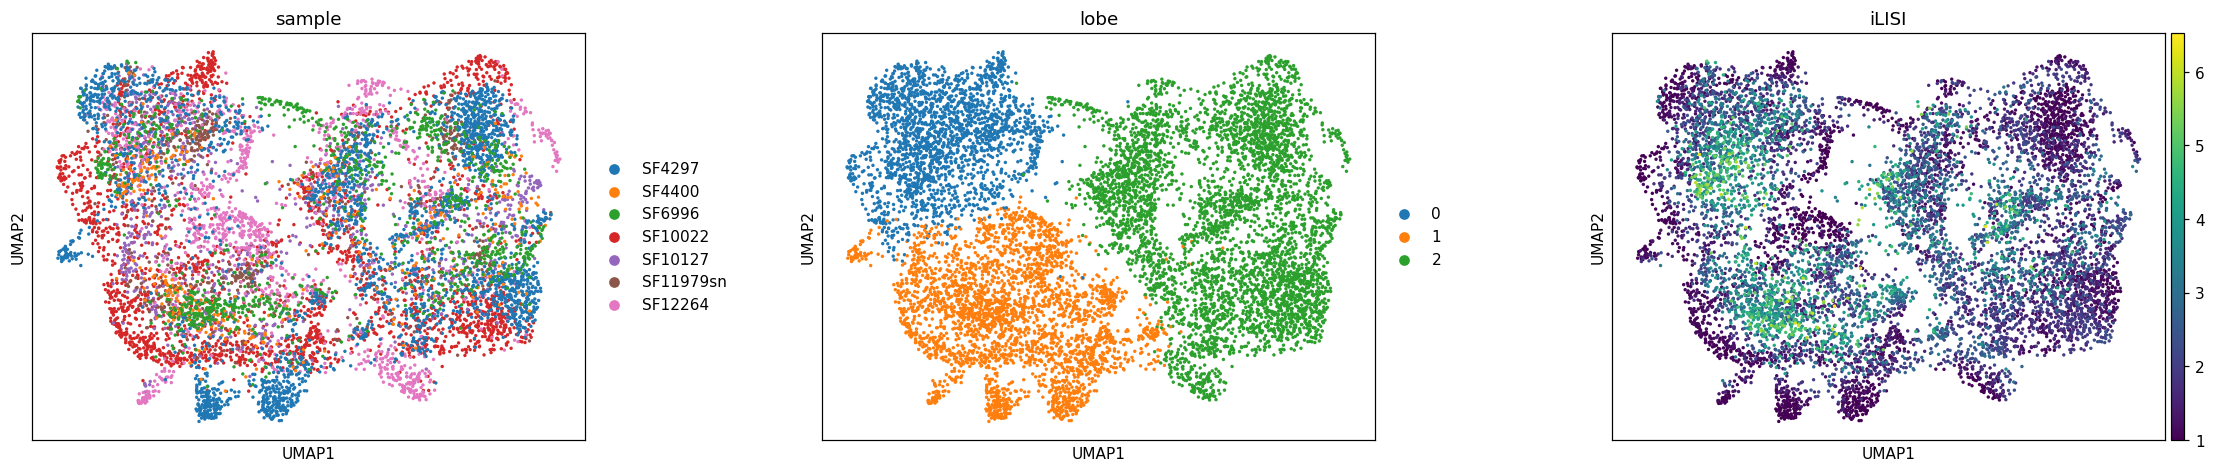

In [8]:
fig = sc.pl.umap(adata, color=['sample','lobe','iLISI'], size=20, wspace=.3,
                 cmap='viridis', show=False)
n_samp = adata.obs['sample'].nunique()
# show, do not assert: lobe composition (archipelago test) + integration magnitude
ct = pd.crosstab(adata.obs['lobe'], adata.obs['sample']); frac = ct.div(ct.sum(1), axis=0)
print('per-lobe dominant-sample share (an archipelago would show a lobe ~1.0 from one patient):')
for l in frac.index:
    print(f'  lobe {l}: n={int(ct.loc[l].sum())} dominant {frac.loc[l].idxmax()}={frac.loc[l].max():.2f} '
          f'| samples>=5% = {int((frac.loc[l]>=0.05).sum())}/{n_samp}')
from scipy.sparse.csgraph import connected_components as _cc
print('connected components on the neighbour graph =', _cc(adata.obsp['connectivities'], directed=False)[0])
il = adata.obs['iLISI'].values
print(f'iLISI median {np.median(il):.2f}/{n_samp} (mean {il.mean():.2f}); frac cells iLISI>=2 = {(il>=2).mean():.2f}')
print('read: 1 connected component + every lobe multi-sample (no monochrome island) + '
      'same-sample frac 0.99->~0.6; residual local patient identity is expected GBM CNV structure, not an archipelago')
print('Gate 1: continuous, archipelago-free, multi-sample manifold -> GO')

### Save processed data
The publication carries a few free-text metadata columns (e.g. empty cell-cycle-score fields)
that mix numbers and blank strings; these object columns are coerced to string so the h5ad
serialises cleanly.

In [9]:
for c in adata.obs.columns:
    if adata.obs[c].dtype == object:
        adata.obs[c] = adata.obs[c].astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9634, 26409)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)` horizontal strip, `size=30`) to match every other trajectory
panel. Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence.
The pseudotime left→right orientation is derived in 02 and applied consistently across all
deliverable UMAPs; here (categorical panel) we present the raw embedding on which Gate 1 is
judged.

saved samples.pdf | cells: 9634


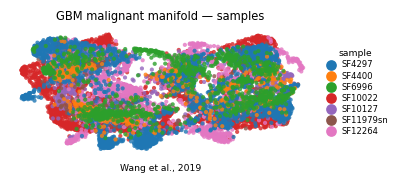

In [10]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('GBM malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])